In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def mod_F(theta):
    """Modified F(theta) for the SMBHB background from galaxies."""
    return 0.5 * (1 + np.cos(theta))

In [ ]:
def mod_T(alpha, omega_hat, p_hat):
    """Modified T(alpha, omega_hat, p_hat) for the SMBHB background from galaxies."""
    complex_term = -2j * alpha * np.pi * (1 + np.dot(omega_hat, p_hat))
    return np.abs(1 - np.exp(complex_term))


In [7]:
mod_T(alpha=1.0, omega_hat=np.array([1, 0, 0]), p_hat=np.array([0, 1, 0]))

np.float64(4.898587196589413e-16)

(0.001, 3)

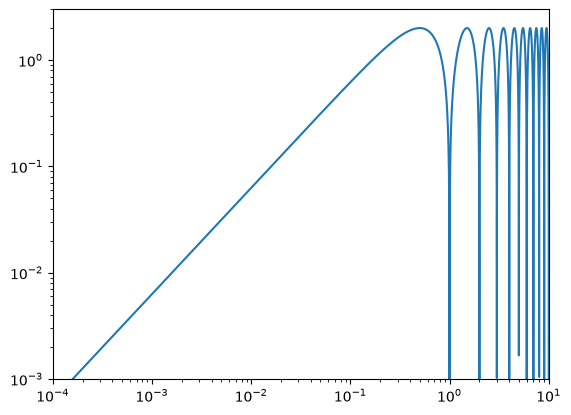

In [21]:
omega_hat_x_vals = np.linspace(0, np.pi, 100)
omega_hat_arr = np.array([np.cos(omega_hat_x_vals), np.sin(omega_hat_x_vals), np.zeros_like(omega_hat_x_vals)]).T
alpha_vals = np.logspace(-4, 1, 100000)
p_hat = np.array([0, 1, 0])
omega_hat = np.array([1, 0, 0])
plt.loglog(alpha_vals, mod_T(alpha=alpha_vals, omega_hat=omega_hat, p_hat=p_hat))
plt.xlim(1e-4, 10)
plt.ylim(1e-3, 3)

In [22]:
def response_function(alpha, omega_hat, p_hat, theta):
    """Response function for the SMBHB background from galaxies."""
    return mod_F(theta) * mod_T(alpha, omega_hat, p_hat)

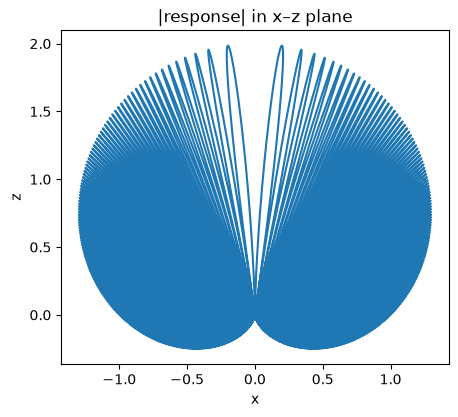

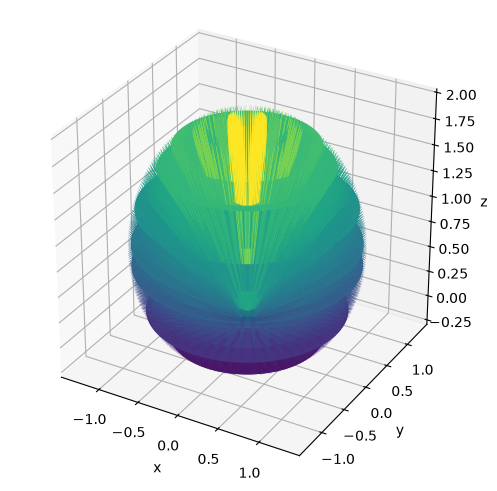

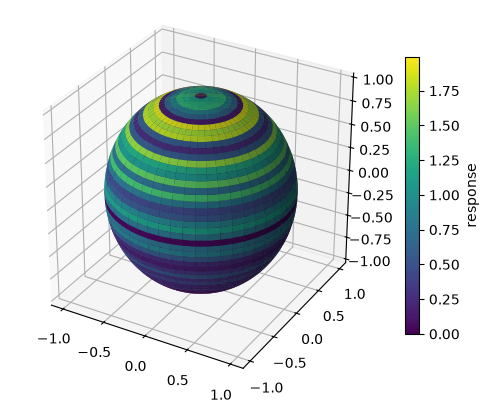

In [37]:
theta = np.linspace(1e-5, np.pi, 10000)
alpha = 100
p_hat = np.array([0, 0, 1])                      # pulsar on z axis

omega = np.stack([np.sin(theta), np.zeros_like(theta), np.cos(theta)], axis=1)
R = np.array([response_function(alpha, w, p_hat, t) for w, t in zip(omega, theta)])

# ---------- 1) x–z plane (polar-style cross-section) ----------
# mirror to cover x<0 as well (symmetry)
th_full = np.concatenate([theta, theta[::-1]])
R_full  = np.concatenate([R, R[::-1]])
sign    = np.concatenate([np.ones_like(theta), -np.ones_like(theta)])  # x -> -x

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(sign * np.abs(R_full) * np.sin(th_full), np.abs(R_full) * np.cos(th_full))
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title("|response| in x–z plane")

# ---------- 2) 3D surface of revolution about z ----------
phi = np.linspace(0, 2*np.pi, 200)
TH, PH = np.meshgrid(theta, phi)
RR = np.tile(np.abs(R), (len(phi), 1))           # no recompute needed: symmetric in phi

X = RR * np.sin(TH) * np.cos(PH)
Y = RR * np.sin(TH) * np.sin(PH)
Z = RR * np.cos(TH)

fig = plt.figure(figsize=(6, 6))
ax3 = fig.add_subplot(projection="3d")
ax3.plot_surface(X, Y, Z, cmap="viridis", linewidth=0)
ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("z")
ax3.set_box_aspect((1, 1, 1))

# ---------- 3) Alternative: color a unit sphere by the response ----------
from matplotlib import cm, colors
Xs, Ys, Zs = np.sin(TH)*np.cos(PH), np.sin(TH)*np.sin(PH), np.cos(TH)
Rg = np.tile(R, (len(phi), 1))
norm = colors.Normalize(Rg.min(), Rg.max())

fig = plt.figure(figsize=(6, 6))
ax4 = fig.add_subplot(projection="3d")
ax4.plot_surface(Xs, Ys, Zs, facecolors=cm.viridis(norm(Rg)), linewidth=0)
fig.colorbar(cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax4, shrink=0.6, label="response")
ax4.set_box_aspect((1, 1, 1))
plt.show()

peak angles (rad): [0.06268572 0.10862489 0.14028392 0.16604266 0.1883379 ]
peak angles (deg): [ 3.59162735  6.22374775  8.03767646  9.51354376 10.79096661]
analytic (rad):    [0.06269822 0.10863213 0.14028954 0.16604743 0.18834211]
peak heights:      [1.9980355  1.99410572 1.99017594 1.98624617 1.98231639]


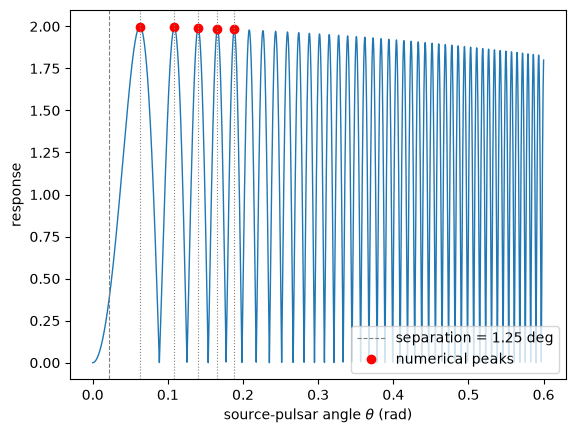

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar

alpha = alpha_58
p_hat = np.array([0.0, 0.0, 1.0])               # pulsar on z axis

def R_of_theta(theta):
    """theta = angle between GW source direction and pulsar direction."""
    omega_hat = -np.array([np.sin(theta), 0.0, np.cos(theta)])   # propagation dir = -source dir
    return response_function(alpha, omega_hat, p_hat, theta)

theta = np.linspace(1e-5, 0.6, 20000)
R = np.array([R_of_theta(t) for t in theta])

# ---- coarse peaks ----
idx, _ = find_peaks(R)

# ---- refine ----
n_peaks = 5
dth = theta[1] - theta[0]
peaks = []
for i in idx[:n_peaks]:
    lo, hi = max(theta[i] - dth, theta[0]), min(theta[i] + dth, theta[-1])
    res = minimize_scalar(lambda t: -R_of_theta(t), bounds=(lo, hi),
                          method="bounded", options={"xatol": 1e-12})
    peaks.append(res.x)
peaks = np.array(peaks)
heights = np.array([R_of_theta(t) for t in peaks])

# ---- analytic comparison (ignores the mod_F prefactor) ----
n = np.arange(len(peaks))
theta_analytic = np.arccos(1 - (n + 0.5) / alpha)

print("peak angles (rad):", peaks)
print("peak angles (deg):", np.degrees(peaks))
print("analytic (rad):   ", theta_analytic)
print("peak heights:     ", heights)

# ---- plot ----
plt.plot(theta, R, lw=1)
separtion = 1.25 # degrees
plt.axvline(np.radians(separtion), color="gray", ls="--", lw=0.8, label=f"separation = {separtion} deg")
plt.plot(peaks, heights, "ro", label="numerical peaks")
for t in theta_analytic:
    plt.axvline(t, color="gray", ls=":", lw=0.8)
plt.xlabel(r"source-pulsar angle $\theta$ (rad)")
plt.ylabel("response")
plt.legend()
plt.show()

## J0125-2327
Distance: 873 pc

RA: 01h 25m 10s

Dec: -23deg 27min 26sec

### Source:
Separation: 1.250665 degrees

f = 2.041752544812425e-09 Hz

$\alpha = fL = L/\lambda = (873 \mathrm{pc} \times 3.086\times10^{16} \mathrm{m/pc})/(2.998 \mathrm{m/s}/2.042\times 10{^-9} \mathrm{s}^{-1})$

In [61]:
f = 2.041752544812425e-09 # frequency of GW in Hz
pc = 3.085677581491367e16
L = 873 * pc  # distance to pulsar in meters
c = 299792458  # speed of light in m/s
lambda_ = c / f  # wavelength of GW in meters
print("lambda =", lambda_/pc, "pc")
alpha = L/lambda_  # dimensionless parameter
print("alpha =", alpha)

lambda = 4.758466893975521 pc
alpha = 183.46245113216312


## J2124-3358
Distance = 410 pc

In [62]:
f_58 = 6.0300111570654735e-09
L_58 = 410 * pc  # distance to pulsar in meters
lambda_58 = c / f_58  # wavelength of GW in meters
print("lambda_58 =", lambda_58/pc, "pc")
alpha_58 = L_58/lambda_58  # dimensionless parameter
print("alpha_58 =", alpha_58)

lambda_58 = 1.6112096042801243 pc
alpha_58 = 254.46720210135837
